# Буткемп, электронный relative-value трейдинг, день 16 — order lifecycle и три queue-модели

Задание: взять результаты предыдущей домашки (reservation price и optimal width) и добавить моделирование очередей тремя моделями, отмеченными на слайде:

1. **Base (Poisson, unit size)** — филлы единичного размера, трейды как пуассоновский поток; fill probability и expected fill time в закрытой форме.
2. **+ Cancellations (thinning)** — впереди стоят и трейды, и отмены; суммарный поток $\lambda=\lambda_T+\lambda_C$, thinning на трейды/отмены; очередь опустошается быстрее, но заполняет только трейд.
3. **Hawkes process** — самовозбуждающийся поток: интенсивность $\mu+\sum_i\alpha e^{-\beta(t-t_i)}$, branching ratio $n=\alpha/\beta<1$; кластеризация и бёрсты.

Инструмент тот же: BTC-USDT на Bybit, 100-мс top-of-book и трейды **только BTCUSDT** за 2026-07-01 12:00–12:30 UTC. Моделируем **одну котировку на bid** (ask симметричен): очередь в BTC, горизонт 10 секунд — тот же, что в hw15. Для каждой модели считаем fill probability, expected fill time и **итоговый PnL** на 1 000 котировок, плюс график накопленного PnL.

## Данные и оценки очереди

Все параметры оцениваем для bid-стороны:

- $\lambda_T$ — интенсивность трейдов, которые бьют в bid, в BTC/с: раз очередь стоит в BTC, то и поток должен быть объёмным, а не событийным;
- $\lambda_C$ — интенсивность отмен впереди нас; считаем её прокси по тому уменьшению displayed depth, которое не объясняется трейдами, тоже в BTC/с;
- $Q_0$ — медианная глубина bid-очереди в BTC;
- $\mathrm{UNIT}$ — средний размер такого трейда; он нужен только чтобы перевести $Q_0$ в события для Hawkes;
- markout — замер через 10 секунд после филла, в тиках.

Одна сторона — не экономия, а необходимость: котировка живёт либо на bid, либо на ask, а если свалить трейды обеих сторон в один $\lambda_T$, интенсивность завысится примерно вдвое. Ask симметричен, так что считаем bid и не дублируем работу.

Прокси отмен по top-of-book — это **верхняя оценка**. Стоит исключить шаги, на которых меняется best price, как она падает почти до нуля: значит, отмены на touch из top-of-book отдельно от сдвига уровня не идентифицируются. Поэтому весь thinning ниже — сценарий с завышенным $\lambda_C$, а не точная калибровка.

In [1]:
import duckdb, numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt
from scipy.stats import poisson, gamma
warnings.filterwarnings('ignore')
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

D = '/Users/b.kotov/Downloads/'
Q = D + 'l2_executable_quotes_100ms_10000.parquet'
T0 = '2026-07-01 12:00:00+00'; T1 = '2026-07-01 12:30:00+00'
con = duckdb.connect()
panel = con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
 FROM read_parquet('{Q}') WHERE asset='BTC' AND exchange='Bybit'
 AND event_time >= TIMESTAMPTZ '{T0}' AND event_time < TIMESTAMPTZ '{T1}' ORDER BY event_time""").df().reset_index(drop=True)
trades = con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time >= TIMESTAMPTZ '{T0}' AND event_time < TIMESTAMPTZ '{T1}' ORDER BY event_time""").df()
tick = 0.1; n = len(panel)
bb=panel.best_bid.values; ba=panel.best_ask.values; bba=panel.best_bid_amount.values; baa=panel.best_ask_amount.values; mid=panel.mid.values
pt=np.array(panel.event_time.astype('int64')); tt=np.array(trades.event_time.astype('int64'))
ib=np.searchsorted(pt,tt,side='right')-1; ok=(ib>=0)&(ib<n); ib=ib[ok]; trades=trades.iloc[np.where(ok)[0]].reset_index(drop=True)
px=trades.price.values; amt=trades.amount.values; idx=ib

# одна сторона: bid. Трейд «бьёт в bid», если его цена равна best_bid
is_bid = np.abs(px-bb[idx]) <= tick/2
LAM_T_EV = is_bid.sum()/1800.0          # событий/с
LAM_T    = amt[is_bid].sum()/1800.0     # BTC/с
UNIT     = float(amt[is_bid].mean())    # BTC на событие
Q0       = float(np.median(bba))        # медианная очередь впереди, BTC

# отмены на bid: уменьшение displayed depth, не объяснённое трейдами
bid_trade_vol=np.zeros(n)
for j in np.where(is_bid)[0]:
    bid_trade_vol[idx[j]] += amt[j]
depth_dec=np.maximum(-np.diff(bba,prepend=bba[0]),0)
LAM_C=np.maximum(depth_dec-bid_trade_vol,0).sum()/1800.0  # верхняя оценка
bid_price_moved=np.r_[False, np.diff(bba)!=0]
LAM_C_FILT=np.maximum(np.where(bid_price_moved,0.0,depth_dec)-bid_trade_vol,0).sum()/1800.0

# markout через 10 с после филла на bid
MO=[]
for j in np.where(is_bid)[0]:
    k=idx[j]
    if k+100>=n: continue
    MO.append((mid[k+100]-bb[k])/tick)
MO=np.array(MO)

print('bid-трейдов: %d, событийная λ_T = %.2f/с, объёмная λ_T = %.3f BTC/с' % (is_bid.sum(),LAM_T_EV,LAM_T))
print('λ_C = %.3f BTC/с (верхняя оценка), без шагов со сменой best price — %.3f BTC/с' % (LAM_C,LAM_C_FILT))
print('Q0 (median bid depth) = %.2f BTC, UNIT = %.4f BTC' % (Q0,UNIT))
print('markout на bid за 10 с: mean %.1f, median %.1f тиков (n=%d)' % (MO.mean(),np.median(MO),len(MO)))

bid-трейдов: 13091, событийная λ_T = 7.27/с, объёмная λ_T = 0.277 BTC/с
λ_C = 2.262 BTC/с (верхняя оценка), без шагов со сменой best price — 0.000 BTC/с
Q0 (median bid depth) = 2.30 BTC, UNIT = 0.0380 BTC
markout на bid за 10 с: mean -42.9, median -20.5 тиков (n=13076)


## Base (Poisson, unit size)

Впереди нас $Q_0$ BTC очереди, которую размывают трейды с объёмной интенсивностью $\lambda_T$ BTC/с; в unit-size приближении каждый трейд уносит ровно единицу объёма. Значит, время до филла — Gamma($Q_0,\lambda_T$) (для целого $Q_0$ — Erlang):

$$
P(\text{fill by }h)=P(\text{Poisson}(\lambda_T h)\ge Q_0),
\qquad
E[T]=\frac{Q_0}{\lambda_T}.
$$

Подставляем $Q_0=2.30$ BTC (медиана глубины bid) и $\lambda_T=0.277$ BTC/с — выходит $E[T]\approx8.3$ с; почти весь горизонт. Горизонты считаем на 0.1/0.5/1/5/10 секундах.

In [2]:
HORIZONS = [0.1, 0.5, 1.0, 5.0, 10.0]
base_rows=[]
for h in HORIZONS:
    p = float(gamma.cdf(h, a=Q0, scale=1/LAM_T))
    base_rows.append({'h, s':h, 'P(fill base)':round(p,3), 'E[T] base, s':round(Q0/LAM_T,3)})
BASE = pd.DataFrame(base_rows)
display(BASE)

,"h, s",P(fill base),"E[T] base, s"
0,0.1,0.000,8.309
1,0.5,0.004,8.309
2,1.0,0.016,8.309
3,5.0,0.315,8.309
4,10.0,0.694,8.309


## + Cancellations (thinning)

Теперь очередь опустошают два независимых пуассоновских потока: трейды $\lambda_T$ и отмены $\lambda_C$, оба в BTC/с. Суммарный поток — $\lambda=\lambda_T+\lambda_C$; каждое событие с вероятностью $\lambda_T/\lambda$ является трейдом. Чтобы дойти до фронта, нужно $Q_0-1$ BTC опустошений, после чего ждём трейд:

$$
E[T]=\frac{Q_0-1}{\lambda_T+\lambda_C}+\frac{1}{\lambda_T}.
$$

При $\lambda_C=2.26$ BTC/с суммарный темп опустошения в $(\lambda_T+\lambda_C)/\lambda_T\approx9.2$ раза выше, а $E[T]$ падает с 8.31 до 4.13 с — вдвое; если же $\lambda_C\to0$ (после исключения сдвигов уровня), thinning вырождается в base. Это две границы для скорости опустошения, а не две точные оценки. Fill probability считаем симуляцией (20 000 путей).

In [3]:
rng=np.random.default_rng(7)
def thin_fill_time(Q, lamT, lamC, rng, n_paths=20000):
    # Q-1 BTC опустошают трейды+отмены, затем ждём трейд
    return rng.gamma(Q-1, 1/(lamT+lamC), n_paths) + rng.exponential(1/lamT, n_paths)
THIN_SIM = thin_fill_time(Q0, LAM_T, LAM_C, rng)
thin_rows=[]
for h in HORIZONS:
    thin_rows.append({'h, s':h, 'P(fill thinning)':round(float(np.mean(THIN_SIM<=h)),3)})
THIN = pd.DataFrame(thin_rows)
E_THIN=(Q0-1)/(LAM_T+LAM_C)+1/LAM_T
THIN['E[T] thinning, s']=round(E_THIN,3)
display(THIN)
print('сравнение E[T]: base %.2f с, thinning %.2f с (быстрее на %.1f%%)' % (
    Q0/LAM_T, E_THIN, 100*(1-E_THIN/(Q0/LAM_T))))

,"h, s",P(fill thinning),"E[T] thinning, s"
0,0.1,0.001,4.126
1,0.5,0.043,4.126
2,1.0,0.133,4.126
3,5.0,0.709,4.126
4,10.0,0.927,4.126


сравнение E[T]: base 8.31 с, thinning 4.13 с (быстрее на 50.3%)


## Hawkes process

Трейд на bid собирается в кластеры: Fano factor (дисперсия к среднему числа событий в 100-мс бинах) вместе с автокорреляцией показывают, что Пуассон бёрсты недооценивает. Hawkes калибруем по моментам:

- branching ratio $n=1-1/\text{Fano}$, где Fano — по 100-мс бинам bid-трейдов;
- $\mu=\lambda_T^{ev}(1-n)$, здесь $\lambda_T^{ev}$ — событийная интенсивность;
- $\beta$ подгоняем по автокорреляции соседних 100-мс бинов: $\rho_1\approx n e^{-\beta\Delta}$, откуда $\alpha=n\beta$.

Потом симулируем Hawkes методом Ogata thinning с event rate $\lambda_T^{ev}=7.27$ событий/с. Очередь у нас в BTC, поэтому $Q_0$ переводим в события: $Q_{ev}=Q_0/\mathrm{UNIT}\approx60$ трейдов. Время филла — это момент $Q_{ev}$-го события после случайно выбранной постановки котировки. Кластеризация утяжеляет распределение: в бёрстах филл приходит быстро, зато в тишине приходится ждать долго.

In [4]:
# Fano and lag-1 autocorrelation of bid touch trade counts in 100ms bins
ev=np.sort(trades.event_time.values[is_bid].astype('datetime64[ns]').astype('int64')/1e9); ev=ev-ev[0]
T_end=float(ev[-1]); bins=np.arange(0,T_end+0.1,0.1); cnt=np.histogram(ev,bins)[0]
FANO=float(cnt.var()/cnt.mean()); RHO1=float(np.corrcoef(cnt[:-1],cnt[1:])[0,1])
N_BRANCH=float(min(0.99, max(0.01, 1-1/FANO)))
MU=LAM_T_EV*(1-N_BRANCH)
BETA=float(max(0.1, -np.log(max(RHO1/N_BRANCH,1e-6))/0.1))
ALPHA=N_BRANCH*BETA
print('Hawkes moments: Fano=%.2f, rho1=%.3f -> n=%.3f, mu=%.2f/s, beta=%.1f/s, alpha=%.1f/s' % (FANO,RHO1,N_BRANCH,MU,BETA,ALPHA))

def sim_hawkes(T, mu, alpha, beta, rng):
    out=[]; t=0.0; last=0.0; R=0.0
    while True:
        lam_star=mu+alpha*R
        if lam_star<=0: break
        t += rng.exponential(1/lam_star)
        if t>=T: break
        R_t=R*np.exp(-beta*(t-last))
        lam=mu+alpha*R_t
        if rng.random() < lam/lam_star:
            out.append(t); R=R_t+1.0; last=t
    return np.array(out)

rng=np.random.default_rng(11)
HAWK=sim_hawkes(20000, MU, ALPHA, BETA, rng)
Q_EV=int(round(Q0/UNIT))
print('Hawkes simulated events: %d, mean rate %.2f/s (target %.2f); Q_ev=%d' % (len(HAWK), len(HAWK)/20000, LAM_T_EV, Q_EV))

# fill time: Q_EV-е событие после случайного момента постановки
starts=rng.uniform(0,19950,20000)
i0=np.searchsorted(HAWK,starts)
valid=i0+Q_EV-1 < len(HAWK)
HAWK_FILL=np.full(len(starts),np.inf)
HAWK_FILL[valid]=HAWK[i0[valid]+Q_EV-1]-starts[valid]
print('Hawkes: P(fill in 1 s)=%.3f, P(fill in 5 s)=%.3f, P(fill in 10 s)=%.3f, E[T | fill within simulation]=%.2f s' % (
    float(np.mean(HAWK_FILL<=1.0)), float(np.mean(HAWK_FILL<=5.0)), float(np.mean(HAWK_FILL<=10.0)),
    float(np.mean(HAWK_FILL[np.isfinite(HAWK_FILL)]))))

Hawkes moments: Fano=14.98, rho1=0.118 -> n=0.933, mu=0.49/s, beta=20.7/s, alpha=19.3/s


Hawkes simulated events: 148252, mean rate 7.41/s (target 7.27); Q_ev=60
Hawkes: P(fill in 1 s)=0.033, P(fill in 5 s)=0.157, P(fill in 10 s)=0.326, E[T | fill within simulation]=17.43 s


## Итоговый PnL: одна bid-котировка, горизонт 10 секунд

Стратегия одна и та же во всех моделях: котировка на bid с очередью $Q_0=2.30$ BTC, размер 1 BTC, горизонт 10 секунд. Если филл произошёл, PnL на филл = markout за 10 с минус комиссия maker $0.1$ bp (в тиках). Markout включает half-spread на входе и берётся эмпирически; в графике разыгрываем его из эмпирического распределения.

Итоговый PnL на 1 000 котировок = $1000\cdot P(\text{fill})\cdot(\overline{\text{markout}}-\text{fee})$. Ниже — таблица и график накопленного PnL по трём моделям. На графике показана одна реализация розыгрыша филлов и markout, поэтому его итог отличается от аналитической таблицы на 5–20% (сильнее всего у Hawkes, где филлов мало); таблица — это ожидаемый PnL.

комиссия maker 0.1 bp = 5.85 тиков; markout mean -42.9, median -20.5 тиков


,model,P(fill in 10s),E[fills per 1k],"PnL per 1k, ticks"
0,base,0.694,694.0,-33875.4
1,thinning,0.927,927.0,-45244.6
2,hawkes,0.326,326.0,-15907.7


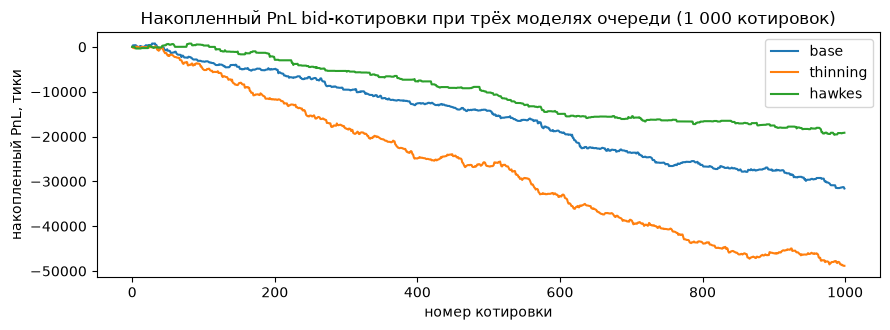

base      final PnL over 1,000 quotes: -31591.4 ticks
thinning  final PnL over 1,000 quotes: -48839.4 ticks
hawkes    final PnL over 1,000 quotes: -19158.5 ticks


In [5]:
FEE_T=0.1e-4*float(np.mean(mid))/tick
P_FILL={}
P_FILL['base']=float(gamma.cdf(10.0, a=Q0, scale=1/LAM_T))
P_FILL['thinning']=float(np.mean(THIN_SIM<=10.0))
P_FILL['hawkes']=float(np.mean(HAWK_FILL<=10.0))
MARK_MEAN=float(MO.mean()); MARK_MED=float(np.median(MO))
print('комиссия maker 0.1 bp = %.2f тиков; markout mean %.1f, median %.1f тиков' % (FEE_T,MARK_MEAN,MARK_MED))
rows=[]
for name,p in P_FILL.items():
    rows.append({'model':name,'P(fill in 10s)':round(p,3),'E[fills per 1k]':round(1000*p,0),
                 'PnL per 1k, ticks':round(1000*p*(MARK_MEAN-FEE_T),1)})
PNL=pd.DataFrame(rows); display(PNL)

# simulated sequential PnL chart: 1000 quotes, Bernoulli fill, markout sampled empirically
rng=np.random.default_rng(21)
curve={}
for name,p in P_FILL.items():
    fills=rng.random(1000)<p
    mo_s=rng.choice(MO,size=1000,replace=True)
    pnl=np.where(fills, mo_s-FEE_T, 0.0)
    curve[name]=np.cumsum(pnl)
fig,ax=plt.subplots(figsize=(9,3.4))
for name,y in curve.items():
    ax.plot(y,label=name)
ax.set_xlabel('номер котировки'); ax.set_ylabel('накопленный PnL, тики')
ax.set_title('Накопленный PnL bid-котировки при трёх моделях очереди (1 000 котировок)')
ax.legend(); plt.tight_layout(); plt.show()
for name,y in curve.items():
    print('%-9s final PnL over 1,000 quotes: %+.1f ticks' % (name,y[-1]))

## Сводка и вывод

В сводке собрано всё вместе: оценки $\lambda_T$, $\lambda_C$, $Q_0$; fill probabilities трёх моделей на горизонте 10 с; expected fill time; итоговый PnL на 1 000 котировок и его знак.

In [6]:
summary=pd.DataFrame([
 {'что':'λ_T (bid), λ_C, Q0','значение':'%.3f BTC/с, %.3f BTC/с, median %.2f BTC' % (LAM_T,LAM_C,Q0)},
 {'что':'base: P(fill 10s), E[T]','значение':'%.3f, %.2f s' % (P_FILL['base'], Q0/LAM_T)},
 {'что':'thinning: P(fill 10s), E[T]','значение':'%.3f, %.2f s' % (P_FILL['thinning'], E_THIN)},
 {'что':'Hawkes: n, β, P(fill 10s)','значение':'%.3f, %.1f/s, %.3f' % (N_BRANCH,BETA,P_FILL['hawkes'])},
 {'что':'итоговый PnL base / thinning / Hawkes на 1k','значение':'%+.0f / %+.0f / %+.0f тиков' % tuple(PNL['PnL per 1k, ticks'])},
 {'что':'markout (10s, bid) mean / median','значение':'%.1f / %.1f тиков' % (MARK_MEAN,MARK_MED)},
])
display(summary)

,что,значение
0,"λ_T (bid), λ_C, Q0","0.277 BTC/с, 2.262 BTC/с, median 2.30 BTC"
1,"base: P(fill 10s), E[T]","0.694, 8.31 s"
2,"thinning: P(fill 10s), E[T]","0.927, 4.13 s"
3,"Hawkes: n, β, P(fill 10s)","0.933, 20.7/s, 0.326"
4,итоговый PnL base / thinning / Hawkes на 1k,-33875 / -45245 / -15908 тиков
5,"markout (10s, bid) mean / median",-42.9 / -20.5 тиков


## Вывод

Три queue-модели расходятся в **скорости опустошения очереди**, но edge ни одна из них не создаёт:

- base Poisson: при $Q_0=2.30$ BTC и горизонте 10 с $P(\text{fill})\approx0.694$, $E[T]\approx8.3$ с;
- thinning подключает отмены: $P(\text{fill})\approx0.927$, $E[T]\approx4.1$ с — отмены ускоряют доступ к фронту, но филл всё равно требует трейда. Оговорка принципиальная: $\lambda_C=2.26$ BTC/с — верхняя оценка по top-of-book; если убрать шаги со сменой best price, он обваливается до нуля и thinning вырождается в base. То есть 0.927 — это граница «много отмен», а не калибровка;
- Hawkes с калиброванным branching ratio $n\approx0.93$: $P(\text{fill})\approx0.326$, $E[T]\approx17.4$ с. При том же среднем темпе кластеры означают долгие тихие окна, в которых котировка стоит без филла, — и по вероятности филла Hawkes проигрывает даже пуассоновскому base.

Итоговый PnL одной и той же bid-котировки **отрицателен во всех трёх моделях**: markout за 10 с в среднем около $-42.9$ тика (медиана $-20.5$), комиссия 0.1 bp добавляет ещё 5.85 тика, а half-spread на входе приносит лишь около 0.5 тика. На 1 000 котировок набегает примерно $-33.9$ тыс. тиков в base, $-45.2$ тыс. в thinning и $-15.9$ тыс. в Hawkes; накопленный PnL — на графике выше (реализация там одна, поэтому итог графика чуть отличается от таблицы). Модель, которая заполняется быстрее (thinning), делает **больше** филлов и теряет больше; Hawkes теряет меньше всех лишь потому, что реже заполняется. Queue-модель честно объясняет, когда и сколько раз тебя нальют, но отрицательный edge в положительный не превращает.

Это хорошо стыкуется с hw15: там ex-post оптимальная полная ширина в 30-минутном окне вышла 11/15/23 тика для calm/normal/stress при net на ожидаемый филл $+0.76/-0.34/+1.96$ тика. Queue-модель как раз даёт недостающий множитель — вероятность филла: на touch за 10 с это 0.69/0.93/0.33, а markout на touch сильно отрицателен. Прибыльность стоит искать на более широких уровнях, но там ниже $P(\text{fill})$; совместная оптимизация ширины и очереди — следующий шаг.

Ограничения: $\lambda_T,\lambda_C$ оценены по одному 30-минутному окну; отмены измерены прокси по глубине, а не по ленте; markout считается не зависящим от queue-модели (для Hawkes это явное упрощение); комиссия 0.1 bp — допущение оптимистичное (у Bybit maker чаще ближе к 1 bp); Hawkes одномерный, трейды и отмены в нём не разделены; моделируется только одна сторона.